# 07 · Pre-trained Transformers: BERT and GPT-2 (Module IV)

**Theory.** Both are Transformers pre-trained on huge unlabelled corpora, then reused.
**BERT** is a *masked* language model: 15% of input tokens are hidden and it predicts them from
context on **both** sides. That makes it good at *understanding* (classification, QA), and it gives
every token a *contextual* vector. **GPT-2** is an *autoregressive* (causal) language model: it predicts
the next token from the tokens on the **left** only, so it can *generate* text one token at a time.
*Fine-tuning* adds a small classification layer on top of a pre-trained encoder and trains everything
for a few epochs on labelled data. DistilBERT is a 40% smaller BERT trained to mimic BERT's outputs
(knowledge distillation).

**Colab:** this notebook also runs on a Colab T4 GPU. Upload the repo, `pip install -r requirements.txt`,
run `scripts/download_data.py --skip-glove`, then run all cells. `get_device()` picks CUDA and fp16
is switched on automatically.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import src.utils  # FIRST: cache folders

import json
import shutil
import time
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from transformers import (AutoModelForCausalLM, AutoModelForMaskedLM,
                          AutoModelForSequenceClassification, AutoModel, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments)
from gensim.models import KeyedVectors

from src.utils import FAST, MODELS, SEED, get_device, set_seed
from src.data import AG_LABELS, load
from src.evaluate import classification_metrics, plot_confusion, save_results

import datasets, transformers
datasets.disable_progress_bars(); transformers.logging.set_verbosity_error()  # keep outputs readable

device = get_device()
print("device:", device, "| FAST:", FAST)
pd.set_option("display.max_colwidth", 200)

/Users/mihirmandavia/nlp-news/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps | FAST: False


## (a) Fine-tune DistilBERT on AG News
20,000 stratified training rows (`ag_train_20k`), max length 64 tokens, learning rate 2e-5,
batch 32, 2 epochs. Validation on `ag_val` after each epoch; final numbers on the full test set.
Training takes ~20 min on this M3 (about 1 s per step). A saved model is reused unless `RETRAIN = True`.

In [2]:
BASE = "distilbert/distilbert-base-uncased"
MODEL_DIR = MODELS / ("distilbert-agnews-fast" if FAST else "distilbert-agnews")
RETRAIN = False

tokenizer = AutoTokenizer.from_pretrained(BASE)
train_df, val_df, test_df = load("ag_train_20k"), load("ag_val"), load("ag_test")

def to_dataset(df):
    ds = Dataset.from_pandas(df[["text", "label"]].rename(columns={"label": "labels"}), preserve_index=False)
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=64), batched=True,
                  remove_columns=["text"])

train_ds, val_ds, test_ds = to_dataset(train_df), to_dataset(val_df), to_dataset(test_df)
lengths = [len(x) for x in tokenizer(test_df.text.tolist())["input_ids"]]
print(f"train {len(train_ds):,} | val {len(val_ds):,} | test {len(test_ds):,} | "
      f"test docs longer than 64 tokens: {np.mean(np.array(lengths) > 64):.1%}")

train 20,000 | val 2,000 | test 7,600 | test docs longer than 64 tokens: 10.0%


In [3]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    m = classification_metrics(labels, logits.argmax(-1))
    return {"accuracy": m["accuracy"], "macro_f1": m["macro_f1"]}

args = TrainingArguments(
    output_dir=str(MODEL_DIR / "_trainer"), num_train_epochs=2, learning_rate=2e-5,
    per_device_train_batch_size=32, per_device_eval_batch_size=64, weight_decay=0.01,
    eval_strategy="epoch", save_strategy="no",       # no checkpoints: disk space is tight
    logging_steps=100, report_to="none", seed=SEED, dataloader_num_workers=0,
    fp16=torch.cuda.is_available(),                   # mixed precision only on a CUDA GPU
)
info_path = MODEL_DIR / "train_info.json"
if info_path.exists() and not RETRAIN:
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR)
    train_info = json.loads(info_path.read_text())
    print("loaded fine-tuned model from", MODEL_DIR.name, "| recorded training time:",
          f"{train_info['train_time_s'] / 60:.1f} min on {train_info['device']}")
else:
    set_seed()
    model = AutoModelForSequenceClassification.from_pretrained(
        BASE, num_labels=4, id2label=dict(enumerate(AG_LABELS)), label2id={l: i for i, l in enumerate(AG_LABELS)})
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)
    t = time.perf_counter(); trainer.train(); train_s = time.perf_counter() - t
    history = [{k: v for k, v in r.items() if k in ("epoch", "loss", "eval_loss", "eval_accuracy", "eval_macro_f1")}
               for r in trainer.state.log_history]
    trainer.save_model(str(MODEL_DIR)); tokenizer.save_pretrained(str(MODEL_DIR))
    shutil.rmtree(MODEL_DIR / "_trainer", ignore_errors=True)
    train_info = {"train_time_s": round(train_s, 1), "device": str(device), "history": history}
    info_path.write_text(json.dumps(train_info, indent=2))
    print(f"trained in {train_s / 60:.1f} min, saved to {MODEL_DIR.name}")
pd.DataFrame(train_info["history"])

loaded fine-tuned model from distilbert-agnews | recorded training time: 24.1 min on mps


,loss,epoch,eval_loss,eval_accuracy,eval_macro_f1
0,0.6267,0.16,NaN,NaN,NaN
1,0.3029,0.32,NaN,NaN,NaN
2,0.2936,0.48,NaN,NaN,NaN
3,0.2952,0.64,NaN,NaN,NaN
4,0.2714,0.80,NaN,NaN,NaN
5,0.2901,0.96,NaN,NaN,NaN
6,NaN,1.00,0.265593,0.9155,0.9156
7,0.2157,1.12,NaN,NaN,NaN
8,0.1994,1.28,NaN,NaN,NaN
9,0.1993,1.44,NaN,NaN,NaN


### Test-set evaluation (7,600 documents)

In [4]:
# Prediction only: its own arguments without eval_strategy (training's args expect an eval set).
pred_args = TrainingArguments(output_dir=str(MODEL_DIR / "_trainer"), per_device_eval_batch_size=64,
                              report_to="none", fp16=torch.cuda.is_available())
eval_trainer = Trainer(model=model, args=pred_args, data_collator=DataCollatorWithPadding(tokenizer))
t = time.perf_counter()
out = eval_trainer.predict(test_ds)
infer_ms = (time.perf_counter() - t) / len(test_ds) * 1000
pred = out.predictions.argmax(-1)
metrics = classification_metrics(test_df.label, pred, AG_LABELS)
size_mb = sum(f.stat().st_size for f in MODEL_DIR.glob("*.safetensors")) / 1e6
shutil.rmtree(MODEL_DIR / "_trainer", ignore_errors=True)
print(f"accuracy {metrics['accuracy']}  macro-F1 {metrics['macro_f1']}  |  {infer_ms:.2f} ms/doc "
      f"(batched, {device})  |  {size_mb:.0f} MB")
# Note: timings on this laptop were taken while it was using most of its swap memory, so latency is
# pessimistic; a Colab T4 is several times faster.
pd.DataFrame(metrics["per_class"]).T

/Users/mihirmandavia/nlp-news/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


accuracy 0.9174  macro-F1 0.9173  |  18.62 ms/doc (batched, mps)  |  268 MB


,precision,recall,f1-score
World,0.9243,0.9121,0.9181
Sports,0.9708,0.9800,0.9754
Business,0.8906,0.8742,0.8823
Sci/Tech,0.8836,0.9032,0.8933


array([[1733,   43,   68,   56],
       [  20, 1862,   12,    6],
       [  70,    5, 1661,  164],
       [  52,    8,  124, 1716]])

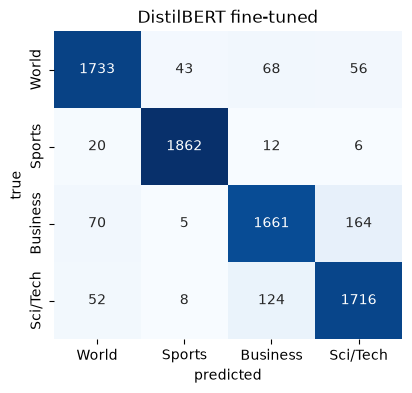

In [5]:
plot_confusion(test_df.label, pred, AG_LABELS, title="DistilBERT fine-tuned")

In [6]:
save_results("distilbert", {
    "dataset": "ag_news", "n_train": len(train_df), "n_test": len(test_df),
    "config": "distilbert-base-uncased fine-tuned, max_len 64, lr 2e-5, batch 32, 2 epochs",
    "device": train_info["device"], "metrics": metrics, "train_time_s": train_info["train_time_s"],
    "infer_ms_per_doc": round(infer_ms, 3), "model_size_mb": round(size_mb, 1),
    "history": train_info["history"], "y_pred": pred,
})
del model, eval_trainer
if device.type == "mps":
    torch.mps.empty_cache()

saved results/distilbert.json


## (b) BERT fill-mask: the prediction depends on context
`bert-base-uncased` scores every vocabulary word for the `[MASK]` position, using words on both sides.

In [7]:
mlm_name = "google-bert/bert-base-uncased"
mlm_tok = AutoTokenizer.from_pretrained(mlm_name)
mlm = AutoModelForMaskedLM.from_pretrained(mlm_name).eval()

@torch.no_grad()
def fill_mask(sentence, k=5):
    enc = mlm_tok(sentence, return_tensors="pt")
    pos = (enc.input_ids[0] == mlm_tok.mask_token_id).nonzero()[0, 0]
    probs = mlm(**enc).logits[0, pos].softmax(-1)
    top = probs.topk(k)
    return ", ".join(f"{mlm_tok.decode([int(i)])} ({p:.2f})" for p, i in zip(top.values, top.indices))

masked = [
    "He went to the [MASK] to withdraw some money.",
    "He went to the [MASK] to catch some fish.",
    "The central bank raised interest [MASK] to fight inflation.",
    "The [MASK] scored twice in the final ten minutes.",
    "The [MASK] approved the new budget after a long debate.",
    "Apple released a new [MASK] with a faster chip.",
]
pd.DataFrame({"sentence": masked, "top-5 predictions (probability)": [fill_mask(s) for s in masked]})

,sentence,top-5 predictions (probability)
0,He went to the [MASK] to withdraw some money.,"bank (0.95), store (0.00), office (0.00), banks (0.00), atm (0.00)"
1,He went to the [MASK] to catch some fish.,"lake (0.29), river (0.21), pond (0.17), creek (0.04), stream (0.03)"
2,The central bank raised interest [MASK] to fight inflation.,"rates (0.92), rate (0.01), money (0.01), payments (0.01), fees (0.00)"
3,The [MASK] scored twice in the final ten minutes.,"team (0.10), visitors (0.03), germans (0.03), lions (0.02), scots (0.02)"
4,The [MASK] approved the new budget after a long debate.,"senate (0.22), legislature (0.20), voters (0.12), assembly (0.11), council (0.08)"
5,Apple released a new [MASK] with a faster chip.,"version (0.53), model (0.10), variant (0.03), product (0.02), edition (0.02)"


Changing one word on the *right* of the mask ("money" vs "fish") changes the prediction. An
autoregressive model reading left to right could not use that word.

## (c) GPT-2 continuation: greedy vs sampling
Same 3 news leads, 40 new tokens each. *Greedy* always takes the most likely token. *Top-k* samples
among the k most likely tokens. *Top-p* (nucleus) samples from the smallest set whose probabilities sum
to p. *Temperature* divides the logits: below 1 = safer, above 1 = more random.

In [8]:
gpt_name = "openai-community/gpt2"
gpt_tok = AutoTokenizer.from_pretrained(gpt_name)
gpt = AutoModelForCausalLM.from_pretrained(gpt_name).eval()

@torch.no_grad()
def continue_text(prompt, seed=SEED, **gen_kwargs):
    torch.manual_seed(seed)
    enc = gpt_tok(prompt, return_tensors="pt")
    out = gpt.generate(**enc, max_new_tokens=40, pad_token_id=gpt_tok.eos_token_id, **gen_kwargs)
    return gpt_tok.decode(out[0, enc.input_ids.shape[1]:], skip_special_tokens=True).replace("\n", " ")

leads = ["The Prime Minister announced on Tuesday that",
         "Shares in the mobile phone maker fell sharply after the company",
         "The England football manager said the team"]
settings = {
    "greedy": dict(do_sample=False),
    "top-k 50, T=1.0": dict(do_sample=True, top_k=50, temperature=1.0),
    "top-p 0.9, T=0.7": dict(do_sample=True, top_p=0.9, top_k=0, temperature=0.7),
    "top-p 0.9, T=1.3": dict(do_sample=True, top_p=0.9, top_k=0, temperature=1.3),
}
gen_rows = [{"lead": lead, "setting": name, "continuation": continue_text(lead, **kw)}
            for lead in leads for name, kw in settings.items()]
gen = pd.DataFrame(gen_rows).set_index(["lead", "setting"])
gen

continuation
lead                                                            setting                                                                                                                                                                                                                  
The Prime Minister announced on Tuesday that                    greedy                             the government would not be able to provide a new tax on the sale of alcohol in the country.  The government has been trying to get the excise duty on alcohol to be reduced by 50 per
                                                                top-k 50, T=1.0                                Russia would supply a $1tn (£750bn) defence industry project to Ukraine and would supply $50bn for a Ukrainian navy. It agreed to help form its own defense industry.   In
                                                                top-p 0.9, T=0.7                             he would seek a referendum on whether to introduce a law to legalize same-sex marriage.  "I am not interested in this referendum," he told reporters.  He also said he would
                                                                top-p 0.9, T=1.3   Russia would investigate a newly commissioned British operating vessel sailed by Israel-based Gearase Inmsford while it employed fuel filtration requirements inside ACM Thomas Cook, Salerno and D...
Shares in the mobile phone maker fell sharply after the company greedy                           's stock fell more than 20 percent in after-hours trading.  The company's shares fell more than 20 percent in after-hours trading after the company's stock fell more than 20 percent in
                                                                top-k 50, T=1.0                    announced it was halting plans to sell its popular iPhone app, which lets users order and pay bills while it's on the road.  Apple's stock price fell more than half a point after the
                                                                top-p 0.9, T=0.7                     announced it was halting plans to sell its popular iPhone app, which it had bought for $1 billion.  The Apple Watch was created in 2011 to replace the Apple Watch, which is worn by
                                                                top-p 0.9, T=1.3   announced customers could choose 3G in 2019. Depending on service industry moves like those of Sprint we can expect an Ultra HD radio player comparable to AC-2 and AWS Salaries will rise 50 percent!
The England football manager said the team                      greedy                                        were "very pleased" with the performance of the players.  "We are very pleased with the performance of the players," he said.  "We are very pleased with the performance of
                                                                top-k 50, T=1.0                          's fans could not be happier with their team's winning record.  "Of course we would love to get a trophy but this is not about an American football team and we are not doing it
                                                                top-p 0.9, T=0.7                           's season was a success.  "It was a great season and we're looking forward to it. We've got the right players in all positions and we're looking forward to our Premier League
                                                                top-p 0.9, T=1.3                      's fairy tales was caused at least in part by failed injections of crucial dosages and would not help. "How do I give this club AC – possibly subsidies, you know – that extra go –

What to notice:
- **Greedy decoding loops.** It repeats the same phrase ("fell more than 20 percent in after-hours
  trading…", "We are very pleased with the performance…"), because the most likely next token keeps
  leading back into the same high-probability phrase.
- **Sampling at T=0.7** is fluent and varied. **At T=1.3** the flattened distribution picks rare tokens
  and the text turns into nonsense.
- **Every version invents facts**: a "$1tn defence project", products and figures, all stated with
  the same confident tone.

### A hallucination example
We ask for a checkable fact. The 2004 Nobel Prize in Literature went to **Elfriede Jelinek**
(Austrian novelist).

In [9]:
fact_prompt = "The 2004 Nobel Prize in Literature was awarded to"
hallucinated = continue_text(fact_prompt, do_sample=False)
print(fact_prompt, "→", hallucinated)
print("mentions Jelinek:", "jelinek" in hallucinated.lower())

The 2004 Nobel Prize in Literature was awarded to →  the late Nobel Prize-winning physicist and Nobel laureate, Albert Einstein.  The Nobel Prize in Physics was awarded to the late Nobel Prize-winning physicist and Nobel laureate, Albert Einstein.  
mentions Jelinek: False


GPT-2 answers with **Albert Einstein**: a physicist who died in 1955, and not the literature laureate.
The sentence is fluent and confident, and it then repeats itself. A language model is
trained to produce *likely text*, not *true text*. It has no source to check against, so it fills
the slot with a plausible-sounding name. The same happens in the news continuations above, which
invent quotes, numbers and events that never occurred.

## (d) "bank" in two contexts: contextual (BERT) vs static (Word2Vec) vectors

In [10]:
bank_sents = {
    "money-1": "He deposited his salary at the bank on Monday.",
    "money-2": "The bank approved the loan for the new factory.",
    "river-1": "They had a picnic on the grassy bank of the river.",
    "river-2": "The boat drifted towards the muddy river bank.",
}
bert = AutoModel.from_pretrained(mlm_name).eval()

@torch.no_grad()
def bank_vector(sentence):
    enc = mlm_tok(sentence, return_tensors="pt")
    pos = enc.input_ids[0].tolist().index(mlm_tok.convert_tokens_to_ids("bank"))
    return bert(**enc).last_hidden_state[0, pos]      # 768-dim vector for this occurrence of "bank"

vecs = {k: bank_vector(s) for k, s in bank_sents.items()}
cos = lambda a, b: float(torch.nn.functional.cosine_similarity(a, b, dim=0))
bert_sim = pd.DataFrame([[cos(vecs[a], vecs[b]) for b in vecs] for a in vecs], index=vecs, columns=vecs).round(3)
print("BERT: cosine similarity between the 'bank' vectors")
bert_sim

BERT: cosine similarity between the 'bank' vectors


,money-1,money-2,river-1,river-2
money-1,1.000,0.812,0.476,0.514
money-2,0.812,1.000,0.395,0.483
river-1,0.476,0.395,1.000,0.815
river-2,0.514,0.483,0.815,1.000


In [11]:
w2v = KeyedVectors.load(str(MODELS / "w2v_ag_skipgram.kv"))  # trained in nb05
static = torch.tensor(w2v["bank"])
print(f"Word2Vec: 'bank' has ONE vector, so every pair has cosine {cos(static, static):.3f}")
print("Word2Vec neighbours of 'bank':", [w for w, _ in w2v.most_similar("bank", topn=8)])

Word2Vec: 'bank' has ONE vector, so every pair has cosine 1.000
Word2Vec neighbours of 'bank': ['banco', 'hispano', 'santander', 'toronto-dominion', 'td.to', 'postbank', 'deutsche', '4,500']


The two money sentences give similar BERT vectors for "bank", and so do the two river sentences,
while money-vs-river pairs are clearly less similar. Word2Vec has a single vector per word type, and
in AG News it is entirely financial (its neighbours are bank names), so the river sense is lost.

In [12]:
save_results("bert_gpt_demos", {
    "fill_mask": dict(zip(masked, [fill_mask(s) for s in masked])),
    "gpt2": gen_rows, "hallucination": {"prompt": fact_prompt, "output": hallucinated,
                                        "true_answer": "Elfriede Jelinek"},
    "bank_bert_cosine": bert_sim.to_dict(), "bank_w2v_neighbours": [w for w, _ in w2v.most_similar("bank", topn=8)],
})

saved results/bert_gpt_demos.json


PosixPath('/Users/mihirmandavia/nlp-news/results/bert_gpt_demos.json')

## Viva notes
**Q1. Masked LM vs autoregressive LM?**
BERT hides random tokens and predicts them from both sides (bidirectional), so it is suited to
understanding tasks and cannot naturally generate left to right. GPT-2 predicts the next token from
the left context only (a causal mask in attention), so it generates text but sees only one side.

**Q2. Why does fine-tuned DistilBERT beat averaged Word2Vec?**
Its vectors are contextual: each word is represented using the whole sentence, and 6 self-attention
layers model word order and interactions. It was pre-trained on billions of words, and fine-tuning
adapts all 66M weights to the task. Averaging static vectors discards order and context.

**Q3. What is a hallucination, and why does it happen?**
Fluent but false output. The model is trained to maximise the likelihood of text, not to check
facts, so when it does not "know" an answer it still produces the most plausible-looking tokens.
Sampling with a high temperature makes it worse.